# Real-to-Sim Sensor Model, Part 6: Export for the Pipeline
| Part | Notebook | What it does |
|---|---|---|
| 1–3 | `12_1` – `12_3` | Camera + CAD render, labels, dataset |
| 4 | `12_4`, `12_4b` | Model: 10 inputs → p, μ, σ per pixel |
| 5 | `12_5` | Any camera pose → simulated noisy scan |
| **6** | **`12_6_real2sim_export`** | **Simulated scans saved exactly like the real ones, for `6_surface_analysis`** |

**The simulated files go through the same steps as the real files:**
```
REAL  camera 1920×1080, ~15 frames in 1 s → merged → 0.5 mm voxels (2_2) → table removed, CAD frame, crop (4_3) → viewpoint_simulated_noise_{i}.pcd
SIM   simulator 1920×1080, 15 frames       → merged → 0.5 mm voxels        → table removed, CAD frame, crop       → viewpoint_simulated_noise_{i}.pcd
```
- **Full resolution.** The model inputs are millimetres and ray angles, so the model works on any grid. Only the noise patch sizes are in pixels; they are doubled (5.5 → 11 px), so the patches keep their size in mm.
- **15 frames.** A real view merges about 15 frames (2_2 records 1 s and keeps every 2nd frame). The frames differ a little ("flicker"), which section 1 measures.
- **Same camera poses** as the 288 real views of each workpiece, so every simulated file has a real twin.
- **Saved to `simulation/test_11_real2sim/{WP}/`**. A new experiment name on purpose: `6_surface_analysis` looks in `simulation/{EXPERIMENT}/{WP}/` *before* `processed_data/`, so saving under `test_11_real_pocket` would silently replace your real scans there.

**What this notebook checks**
1. The frame flicker, measured on the training workpieces.
2. The export of all 4 × 288 views.
3. On the unseen TH1041AV: real and simulated files side by side, point counts, and the Part 5 statistics measured with the same 960×540 ruler.

In [1]:
# ==========================================
# CONFIGURATION
# ==========================================
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d

import real2sim as rs
import real2sim_sim as sim
from seed_utils import SEED

EXPERIMENT = "test_11_real_pocket"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
TEST_WP = "TH1041AV"                                  # never used for fitting anything
TRAIN_WPS = [wp for wp in ALL_WORKPIECES if wp != TEST_WP]
CONFIG_PATH = f"simulation/real2sim/{EXPERIMENT}/simulator_test-{TEST_WP}.json"   # saved by 12_5
EXPORT_EXPERIMENT = "test_11_real2sim"
EXPORT_DIR = f"simulation/{EXPORT_EXPERIMENT}"
OUT_DIR = f"simulation/real2sim/{EXPERIMENT}"
FLICKER_VIEWS = list(range(8, 288, 24))               # 12 views per training workpiece
FLICKER_SIZES = [0.04, 0.06, 0.08, 0.10, 0.12]        # a_mm to try
EXAMPLE_VIEW = 100

cam = rs.Camera.native()            # 1920x1080, like the real scans
cam_ruler = cam.downscaled(2)       # the 960x540 grid of Parts 1-5, used only to measure


def load_workpiece(wp):
    d = rs.real_dirs(EXPERIMENT, wp)
    S = sim.Simulator.from_config(CONFIG_PATH, d["cad"], cam)
    return dict(name=wp, dirs=d, sim=S, T_true=rs.load_cad_pose(EXPERIMENT, wp, refined=True),
                T_avg=rs.load_T_average(d["raw"]), bounds=rs.cad_bounds(S.renderer), views=rs.list_real_views(d["raw"]))


WPS = {wp: load_workpiece(wp) for wp in ALL_WORKPIECES}
S = WPS[TEST_WP]["sim"]
print(f"grid {cam.width}x{cam.height}; noise recipes scaled x{cam.width // 960}: depth {S.depth_noise}, drops {S.drop_noise}")
print({wp: len(w["views"]) for wp, w in WPS.items()}, "views")


def T_base_cam(w, v):
    return np.load(os.path.join(w["dirs"]["raw"], f"view{v}_tf.npy"))


def seed_of(wp, v):
    return np.random.default_rng([SEED, int(wp[2:6]), v])


def real_on_part(w, v, maps):
    # real raw view (camera frame), only the points within 10 mm of the CAD depth at their pixel (the Part 2 rule)
    P = rs.load_real_scan_cam(w["dirs"]["raw"], v)
    return P[rs.near_cad_surface(cam, P, maps, 10.0)]


def two_depth_share(P_cam):
    # share of occupied camera pixels that hold points at two or more whole-mm depths
    u, v, z = cam.project(P_cam)
    ui, vi = np.round(u).astype(np.int64), np.round(v).astype(np.int64)
    ok = (z > 0) & (ui >= 0) & (ui < cam.width) & (vi >= 0) & (vi < cam.height)
    key = np.unique((vi[ok] * cam.width + ui[ok]) * 10000 + np.round(z[ok]).astype(np.int64))
    layers = np.bincount(key // 10000)
    return float(np.mean(layers[layers > 0] > 1))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
grid 1920x1080; noise recipes scaled x2: depth NoiseRecipe(blur_px=11.0, fine_share=0.175, fine_px=2.5), drops NoiseRecipe(blur_px=10.0, fine_share=0.0, fine_px=0.0)
{'TH1021AV': 288, 'TH1031AV': 288, 'TH1041AV': 288, 'TH1051AV': 288} views


## 1. Why one simulated frame is not enough
A real view is **about 15 frames merged**. Each frame is rounded to whole mm on its own. A pixel whose reading sits close to a mm boundary flips between two values from frame to frame, and both survive the 0.5 mm voxels: **two points, one behind the other**. Where this happens often, the real file has many more points.

The model of Parts 4–5 learned the merged scan (the median per pixel), so it does not contain this flicker. One simulated frame has almost no pixels with two depths and too few points.

**The fix:** simulate 15 frames. Each gets a small extra shake before the rounding, of size
`a × (z / 500 mm)² / cos(θ_inc)` (stereo noise grows with distance squared and with slant), and the frames are merged like in 2_2. The size `a` is chosen on the **training workpieces** so that the number of points matches. The share of pixels with two depths is a second, independent number that must then match as well.

,points: simulated / real,pixels with 2+ depths: real,pixels with 2+ depths: simulated
one frame (no flicker),0.750,0.243,0.001
"15 frames, a = 0.04 mm",0.874,0.243,0.148
"15 frames, a = 0.06 mm",0.937,0.243,0.208
"15 frames, a = 0.08 mm",1.001,0.243,0.260
"15 frames, a = 0.10 mm",1.065,0.243,0.306
"15 frames, a = 0.12 mm",1.128,0.243,0.347


chosen: Flicker(a_mm=0.08, frames=15) -> about 0.08 mm per frame at 500 mm facing the camera  (173 s)


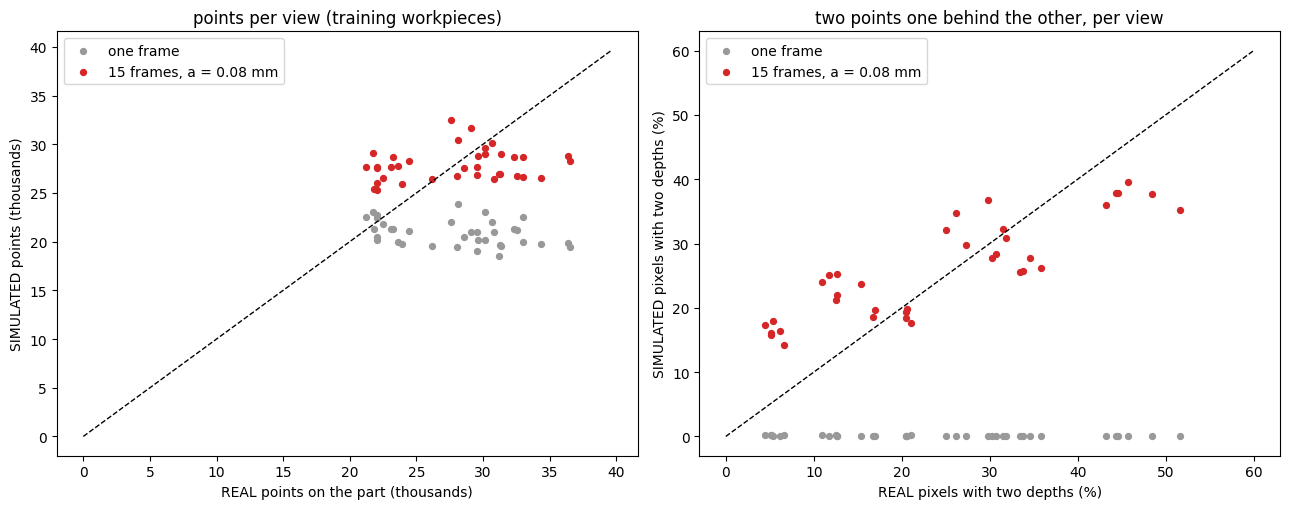

In [2]:
# ==========================================
# 1. FRAME FLICKER, MEASURED ON THE TRAINING WORKPIECES
# ==========================================
t0 = time.time()
cal = []
for wp in TRAIN_WPS:
    w = WPS[wp]
    for v in FLICKER_VIEWS:
        T = T_base_cam(w, v)
        maps = w["sim"].predict_maps(np.linalg.inv(w["T_true"]) @ T)
        P = real_on_part(w, v, maps)
        cal.append(dict(w=w, v=v, T=T, maps=maps, real_n=len(P), real_two=two_depth_share(P)))
rows = []
for a in [0.0] + FLICKER_SIZES:
    for c in cal:   # the same dice for every size (only the flicker size changes)
        Pb, _ = sim.raw_view_cloud(c["w"]["sim"], c["w"]["T_true"], c["T"], seed_of(c["w"]["name"], c["v"]),
                                   sim.Flicker(a), maps=c["maps"])
        rows.append(dict(a=a, workpiece=c["w"]["name"], view=c["v"], real_n=c["real_n"], sim_n=len(Pb),
                         real_two=c["real_two"], sim_two=two_depth_share(rs.transform_points(Pb, np.linalg.inv(c["T"])))))
fit = pd.DataFrame(rows)
g = fit.groupby("a")
flicker_table = pd.DataFrame({"points: simulated / real": g.sim_n.sum() / g.real_n.sum(),
                              "pixels with 2+ depths: real": g.real_two.mean(),
                              "pixels with 2+ depths: simulated": g.sim_two.mean()})
flicker_table.index = ["one frame (no flicker)"] + [f"15 frames, a = {a:.2f} mm" for a in FLICKER_SIZES]
display(flicker_table.round(3))
best_a = FLICKER_SIZES[int(np.argmin(np.abs(flicker_table["points: simulated / real"].values[1:] - 1)))]
FLICKER = sim.Flicker(best_a)
print(f"chosen: {FLICKER} -> about {best_a:.2f} mm per frame at 500 mm facing the camera  ({time.time() - t0:.0f} s)")

one, chosen = fit[fit.a == 0.0], fit[fit.a == best_a]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
ax.scatter(one.real_n / 1000, one.sim_n / 1000, s=18, color="#999999", label="one frame")
ax.scatter(chosen.real_n / 1000, chosen.sim_n / 1000, s=18, color="#d62728", label=f"15 frames, a = {best_a:.2f} mm")
lim = [0, max(fit.real_n.max(), fit.sim_n.max()) / 1000 * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("REAL points on the part (thousands)")
ax.set_ylabel("SIMULATED points (thousands)")
ax.set_title("points per view (training workpieces)")
ax.legend()
ax = axes[1]
ax.scatter(one.real_two * 100, one.sim_two * 100, s=18, color="#999999", label="one frame")
ax.scatter(chosen.real_two * 100, chosen.sim_two * 100, s=18, color="#d62728", label=f"15 frames, a = {best_a:.2f} mm")
ax.plot([0, 60], [0, 60], "k--", lw=1)
ax.set_xlabel("REAL pixels with two depths (%)")
ax.set_ylabel("SIMULATED pixels with two depths (%)")
ax.set_title("two points one behind the other, per view")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part6_flicker.png"), dpi=110)
plt.show()

## 2. Export: all views of all four workpieces
For every real view: simulate from the same camera pose at 1920×1080 with 15 frames, 0.5 mm voxels, then the 4_3 steps:
- **Table removed:** the points less than 2 mm above the table go. The simulation has no table, so its plane is known exactly (z = 0 of the CAD). 4_3 finds the table with RANSAC, which on a simulated view would find the top face instead.
- **CAD frame of `T_average`**, like the real files, so a real file and its simulated twin can be compared directly. (`T_average` sits about 2 mm low and 2° tilted; both kinds of file share that.)
- **Crop** to the CAD bounds + 5 mm.

For TH1041AV the checks of section 3 are collected on the way (real labels, the Part 5 simulation, and the export measured on the 960×540 ruler).

In [3]:
# ==========================================
# 2. EXPORT (+ CHECK DATA FOR THE TEST WORKPIECE)
# ==========================================
wt = WPS[TEST_WP]
ruler = sim.Simulator.from_config(CONFIG_PATH, wt["dirs"]["cad"], cam_ruler)     # Part 5, 960x540, one frame
REGIONS = [("flat (> 5 mm from an edge)", 5, np.inf), ("2-5 mm from an edge", 2, 5), ("right at an edge (< 2 mm)", 0, 2)]
SOURCES = ["real", "Part 5 (960 grid, 1 frame)", "Part 6 export"]
grain = {(reg, s): np.zeros(3) for reg, _, _ in REGIONS for s in SOURCES}
drops = {s: [] for s in SOURCES}
errors = {s: [] for s in SOURCES}
counts = []
t0 = time.time()
for wp in ALL_WORKPIECES:
    w = WPS[wp]
    for k, v in enumerate(w["views"]):
        T = T_base_cam(w, v)
        maps = w["sim"].predict_maps(np.linalg.inv(w["T_true"]) @ T)
        Pb, _ = sim.raw_view_cloud(w["sim"], w["T_true"], T, seed_of(wp, v), FLICKER, maps=maps)
        P_export = sim.process_like_4_3(Pb, w["T_true"], w["T_avg"], w["bounds"])
        sim.save_pcd(os.path.join(EXPORT_DIR, wp, f"viewpoint_simulated_noise_{v}.pcd"), P_export)

        row = dict(workpiece=wp, view=v, sim=len(P_export))
        real_path = os.path.join(w["dirs"]["processed"], f"viewpoint_simulated_noise_{v}.pcd")
        if os.path.exists(real_path):
            real_proc = np.asarray(o3d.io.read_point_cloud(real_path).points)
            on = rs.near_cad_surface(cam, rs.transform_points(real_proc, np.linalg.inv(T) @ w["T_avg"]), maps, 10.0)
            row.update(real=len(real_proc), real_on_part=int(on.sum()))
        if wp == TEST_WP:
            P_real_cam = real_on_part(w, v, maps)
            P_sim_cam = rs.transform_points(Pb, np.linalg.inv(T))
            row.update(real_two=two_depth_share(P_real_cam), sim_two=two_depth_share(P_sim_cam))
            # the same 960x540 ruler as Parts 2-5
            r, lab, ctx, T_cam = rs.view_maps(cam_ruler, ruler.renderer, w["dirs"]["raw"], v, w["T_true"])
            lab6 = rs.make_labels(cam_ruler, r, P_sim_cam, 10.0)
            o5 = ruler.simulate(T_cam, np.random.default_rng([SEED, v]))
            m, edge = r["mask"], ctx["edge_mm"]
            for s, D, E in [(SOURCES[0], lab["y_drop"], lab["e_z"]), (SOURCES[1], o5["drop"].astype(float), o5["e_sim"]),
                            (SOURCES[2], lab6["y_drop"], lab6["e_z"])]:
                drops[s].append(D[m])
                errors[s].append(E[m][np.isfinite(E[m])])
                for a_, b_ in [((slice(None), slice(0, -1)), (slice(None), slice(1, None))),
                               ((slice(0, -1), slice(None)), (slice(1, None), slice(None)))]:
                    diff = E[a_] - E[b_]
                    near = np.minimum(edge[a_], edge[b_])
                    for reg, lo, hi in REGIONS:
                        x = diff[~np.isnan(diff) & (near >= lo) & (near < hi)]
                        grain[(reg, s)] += [len(x), x.sum(), (x ** 2).sum()]
            row.update(real_drop=lab["y_drop"][m].mean(), sim_drop=lab6["y_drop"][m].mean())
        counts.append(row)
        if (k + 1) % 72 == 0:
            print(f"  {wp}: {k + 1}/{len(w['views'])} views  ({time.time() - t0:.0f} s)")
counts = pd.DataFrame(counts)
export_cfg = dict(simulator_config=CONFIG_PATH, grid=[cam.width, cam.height], flicker=dict(a_mm=FLICKER.a_mm, frames=FLICKER.frames),
                  voxel_mm=sim.VOXEL_MM, plane_offset_mm=sim.PLANE_OFFSET_MM, crop_margin_mm=sim.CROP_MARGIN_MM,
                  frame="CAD frame of T_average.npy (like processed_data)", poses="the real views (view{i}_tf.npy, T_cad_refined)",
                  seed=SEED)
with open(os.path.join(EXPORT_DIR, "export_config.json"), "w") as f:
    json.dump(export_cfg, f, indent=2)
print(f"exported {len(counts)} views to {EXPORT_DIR}/<WP>/viewpoint_simulated_noise_<i>.pcd in {time.time() - t0:.0f} s")

  TH1021AV: 72/288 views  (109 s)
  TH1021AV: 144/288 views  (199 s)
  TH1021AV: 216/288 views  (295 s)
  TH1021AV: 288/288 views  (382 s)
  TH1031AV: 72/288 views  (487 s)
  TH1031AV: 144/288 views  (587 s)
  TH1031AV: 216/288 views  (674 s)
  TH1031AV: 288/288 views  (770 s)
  TH1041AV: 72/288 views  (909 s)
  TH1041AV: 144/288 views  (1044 s)
  TH1041AV: 216/288 views  (1177 s)
  TH1041AV: 288/288 views  (1311 s)
  TH1051AV: 72/288 views  (1423 s)
  TH1051AV: 144/288 views  (1513 s)
  TH1051AV: 216/288 views  (1609 s)
  TH1051AV: 288/288 views  (1694 s)
exported 1152 views to simulation/test_11_real2sim/<WP>/viewpoint_simulated_noise_<i>.pcd in 1694 s


## 3. Checks on the unseen TH1041AV
**a. A real file and its simulated twin**, as the camera sees them (colour = distance from the camera). The simulated file should look like the same kind of scan: the same holes along the edges, the same density. The real one also has a few points around the foot of the block (the table "ramp" of Part 5), which the simulator does not make.

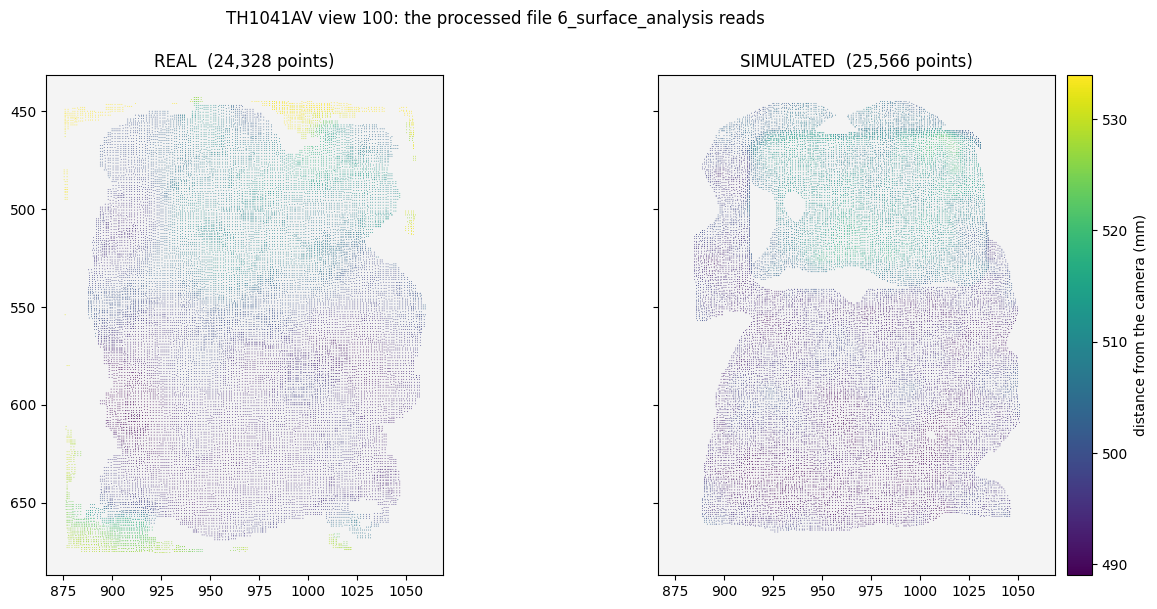

In [4]:
# ==========================================
# 3a. ONE VIEW SIDE BY SIDE
# ==========================================
v = EXAMPLE_VIEW
T = T_base_cam(wt, v)
to_cam = np.linalg.inv(T) @ wt["T_avg"]
clouds = [("REAL", np.asarray(o3d.io.read_point_cloud(os.path.join(wt["dirs"]["processed"], f"viewpoint_simulated_noise_{v}.pcd")).points)),
          ("SIMULATED", np.asarray(o3d.io.read_point_cloud(os.path.join(EXPORT_DIR, TEST_WP, f"viewpoint_simulated_noise_{v}.pcd")).points))]
proj = [(name, *cam.project(rs.transform_points(P, to_cam)), len(P)) for name, P in clouds]
z_lo, z_hi = np.percentile(proj[0][3], [1, 99])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, (name, u, vv, z, n) in zip(axes, proj):
    sc = ax.scatter(u, vv, c=z, s=0.4, cmap="viridis", vmin=z_lo, vmax=z_hi, linewidths=0)
    ax.set_title(f"{name}  ({n:,} points)")
    ax.set_aspect("equal")
    ax.set_facecolor("#f4f4f4")
axes[0].invert_yaxis()
fig.colorbar(sc, ax=axes.tolist(), fraction=0.025, pad=0.01, label="distance from the camera (mm)")
fig.suptitle(f"{TEST_WP} view {v}: the processed file 6_surface_analysis reads")
plt.savefig(os.path.join(OUT_DIR, "part6_side_by_side.png"), dpi=110, bbox_inches="tight")
plt.show()

**b. Points per view.** Left: the simulated files against the real points **on the part** (the real files also hold points off the part, mostly the table ramp; those are counted separately in the table). Right: pixels with two depths, real vs simulated.

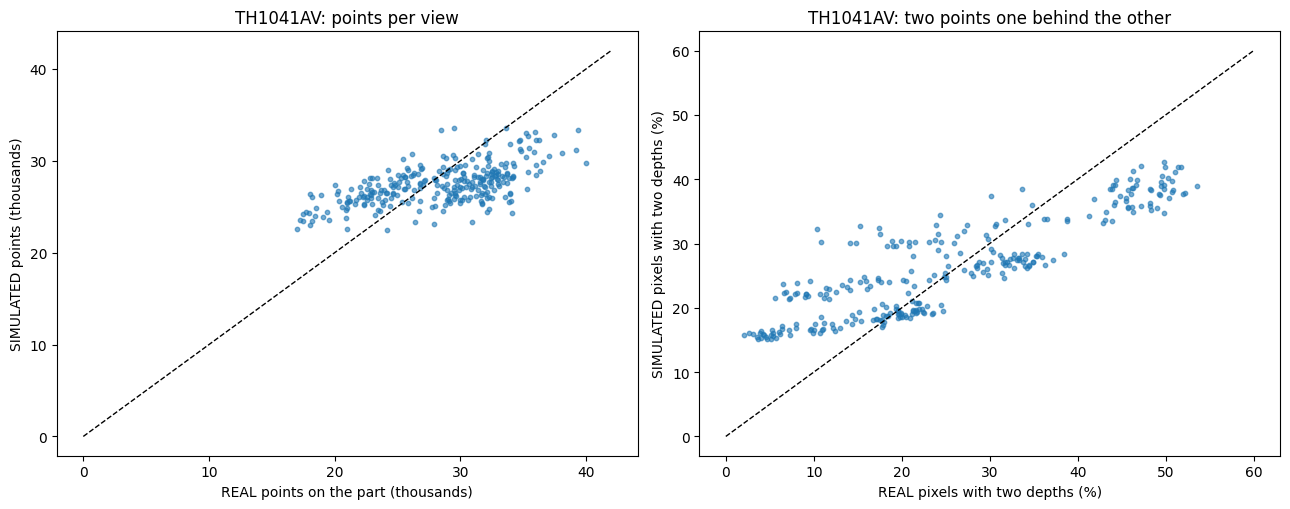

TH1041AV per view: points corr 0.60, two-depth corr 0.87, dropout corr 0.79


,real_total,real_on_part,simulated,simulated / real on part,real points off the part
workpiece,,,,,
TH1021AV,34035.5,28383.0,27982.0,1.011,0.175
TH1031AV,32884.0,28762.5,27295.0,0.990,0.156
TH1041AV,33804.0,29174.0,27357.5,0.968,0.150
TH1051AV,33236.5,29281.0,27156.0,0.969,0.140


In [5]:
# ==========================================
# 3b. POINT COUNTS
# ==========================================
c = counts[counts.workpiece == TEST_WP]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
ax.scatter(c.real_on_part / 1000, c.sim / 1000, s=10, alpha=0.6)
lim = [0, max(c.real_on_part.max(), c.sim.max()) / 1000 * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("REAL points on the part (thousands)")
ax.set_ylabel("SIMULATED points (thousands)")
ax.set_title(f"{TEST_WP}: points per view")
ax = axes[1]
ax.scatter(c.real_two * 100, c.sim_two * 100, s=10, alpha=0.6)
ax.plot([0, 60], [0, 60], "k--", lw=1)
ax.set_xlabel("REAL pixels with two depths (%)")
ax.set_ylabel("SIMULATED pixels with two depths (%)")
ax.set_title(f"{TEST_WP}: two points one behind the other")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part6_counts.png"), dpi=110)
plt.show()
print(f"{TEST_WP} per view: points corr {np.corrcoef(c.real_on_part, c.sim)[0, 1]:.2f}, "
      f"two-depth corr {np.corrcoef(c.real_two, c.sim_two)[0, 1]:.2f}, dropout corr {np.corrcoef(c.real_drop, c.sim_drop)[0, 1]:.2f}")

per_wp = counts.groupby("workpiece").agg(real_total=("real", "median"), real_on_part=("real_on_part", "median"),
                                         simulated=("sim", "median"))
per_wp["simulated / real on part"] = counts.sim.groupby(counts.workpiece).sum() / counts.real_on_part.groupby(counts.workpiece).sum()
per_wp["real points off the part"] = 1 - counts.real_on_part.groupby(counts.workpiece).sum() / counts.real.groupby(counts.workpiece).sum()
display(per_wp.round(3))

**c. The Part 5 statistics, measured with the same 960×540 ruler.** The exported clouds are put back on the grid of Parts 2–5 with the same labelling rule as the real scans. If the higher resolution, the 15 frames or the 0.5 mm voxels had changed the behaviour, it would show here.

In [6]:
# ==========================================
# 3c. SAME RULER AS PARTS 2-5
# ==========================================
rows = {}
for s in SOURCES:
    e = np.concatenate(errors[s])
    rows[s] = [np.mean(np.concatenate(drops[s])), np.median(e), np.quantile(e, 0.1), np.quantile(e, 0.9), e.std()] + \
              [np.sqrt(grain[(reg, s)][2] / grain[(reg, s)][0] - (grain[(reg, s)][1] / grain[(reg, s)][0]) ** 2) for reg, _, _ in REGIONS]
ruler_table = pd.DataFrame(rows, index=["dropout rate", "e_z median (mm)", "e_z 10% (mm)", "e_z 90% (mm)", "e_z std (mm)"] +
                           [f"grain, {reg} (mm)" for reg, _, _ in REGIONS])
display(ruler_table.round(3))

,real,"Part 5 (960 grid, 1 frame)",Part 6 export
dropout rate,0.225,0.228,0.219
e_z median (mm),0.525,0.585,0.484
e_z 10% (mm),-2.966,-3.060,-3.102
e_z 90% (mm),5.101,5.262,5.049
e_z std (mm),3.318,3.438,3.268
"grain, flat (> 5 mm from an edge) (mm)",0.664,0.641,0.679
"grain, 2-5 mm from an edge (mm)",0.846,0.927,0.935
"grain, right at an edge (< 2 mm) (mm)",2.057,1.802,1.884


## Summary of Part 6 (simulator `simulator_test-TH1041AV.json` from 12_5; checks on all 288 views of the unseen TH1041AV)
### Must understand
- **1,152 simulated files are saved:** 288 views × 4 workpieces, in `simulation/test_11_real2sim/{WP}/viewpoint_simulated_noise_{i}.pcd`.
  - Each one has a real twin with the same camera pose and the same index in `processed_data/test_11_real_pocket/{WP}/`.
  - They went through the same steps as the real files: full resolution, about 15 frames merged, 0.5 mm voxels, table removed, CAD frame of `T_average`, crop to the CAD + 5 mm.
  - They sit under a new experiment name on purpose. `6_surface_analysis` looks in `simulation/{EXPERIMENT}/` before `processed_data/`, so a file saved under `test_11_real_pocket` would silently replace a real scan.
- **One simulated frame was not enough** (section 1). A real view merges about 15 frames. Pixels whose reading sits near a whole-mm boundary flip between two values, which gives two points one behind the other.
  - The model of Parts 4–5 learned the merged scan, so it had no such flicker.
  - One frame gave **25% too few points** and almost no doubled pixels (0.1% vs 24% real).
  - The fix is 15 frames with a small extra shake of 0.08 mm × (z / 500 mm)² / cos θ. This one number was measured on the training workpieces. It matches the point count (1.00×) and, independently, the share of doubled pixels (26% vs 24%).
- **The files look like the real ones** (section 3):

  | | Real | Simulated |
  |---|---|---|
  | Points on the part, per view (median, TH1041AV) | 29,174 | 27,358 |
  | Simulated / real points on the part (TH1021 / 1031 / 1041 / 1051) | | 1.01 / 0.99 / 0.97 / 0.97 |
  | Pixels with two depths, per-view correlation | | 0.87 |

- **Measured with the 960×540 ruler of Parts 2–5, nothing changed.** The higher resolution, the 15 frames and the voxels left the behaviour as in Part 5:

  | | Real | Part 5 | Part 6 export |
  |---|---|---|---|
  | Dropout | 22.5% | 22.8% | 21.9% |
  | `e_z` median | +0.53 mm | +0.59 mm | +0.48 mm |
  | `e_z` 10–90% | −3.0 … +5.1 mm | −3.1 … +5.3 mm | −3.1 … +5.0 mm |
  | Grain, flat areas | 0.66 mm | 0.64 mm | 0.68 mm |
  | Grain, at an edge | 2.06 mm | 1.80 mm | 1.88 mm |

  Per-view dropout correlation is 0.79.
- **Known differences:**
  1. **No points off the part.** 14–18% of the points in the real files lie off the part, mostly the table "ramp" at the foot of the walls (Part 5). The simulated files have none.
  2. **Point count per view follows reality only loosely** (correlation 0.60). The real counts range from about 17k to 40k, the simulated ones from about 22k to 34k. Some real views flicker much less, or much more, than distance and slant explain.
  3. **Same frame as the real files.** Both are in the CAD frame of `T_average`, which sits about 2 mm low and 2° tilted. They share this offset, so they compare one to one. Fixing `4_3` to use `T_cad_refined` later would shift both.

### Know what it does
- `real2sim_sim.py`:
  - `NoiseRecipe.scaled`, and `Simulator.from_config` scales the patch sizes to the grid (×2 at 1920×1080);
  - `Flicker` (`a_mm`, `frames`);
  - `raw_view_cloud`: the simulated `view{i}.pcd`, in the robot base frame, merged frames, 0.5 mm voxels;
  - `process_like_4_3`: table, frame, crop;
  - `save_pcd`.
- `simulation/test_11_real2sim/export_config.json` records the settings: flicker, voxel, offsets, frame and seed. Each view uses its own fixed seed (`[42, workpiece number, view]`), so a rerun gives the same files.
- Figures: `part6_flicker.png`, `part6_side_by_side.png`, `part6_counts.png` in `simulation/real2sim/test_11_real_pocket/`.

### Next (check 2)
Run `6_surface_analysis` once on the real files and once on the simulated files, then compare the noise per feature view by view. The question is whether the views that are bad in reality are also bad in simulation.

For the simulated run, set `EXPERIMENT = "test_11_real2sim"`. The perfect clouds (`SIM_DIR`) must still come from `viewpoints_candidate/testing_data/test_11_real_pocket/`.